# 11 daily bias

Validation backtest for this trading module. The tape is synthetic and seeded, so the chart checks that the production rules fire and how the book compounds after 10 bps a side. It is not a live-edge claim.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pipeline.research.validation.figures import draw_module, metrics_frame
from pipeline.research.validation.modules import run_module
from pipeline.research.validation.panel import synthetic_panel

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)


In [2]:
panel = synthetic_panel()
result = run_module('daily_bias', panel)
print(result.title)
for rule in result.rules:
    print("-", rule)
print()
print(result.note)
metrics_frame(result)


Module 10 — daily bias
- Bias is long only when the close is above the SMA50 and MACD is positive and RSI is not extended. One vote stays flat. The mirror is short.
- Levels are classic floor pivots from the prior high, low, and close, plus the prior session range.
- A long stance earns the next close-to-close gain and stays on until the card changes. A short stance earns the opposite.
- Costs are charged when the stance changes, not on every session it stays the same.

Synthetic tape, seeded. Paper costs of 10 bps a side. Not a live-edge claim.


,days,total_return_pct,cagr_pct,sharpe,max_drawdown_pct,n_trades,win_rate_pct,avg_trade_pct
0,420,17.51,10.16,1.73,-4.24,368,47.83,0.532


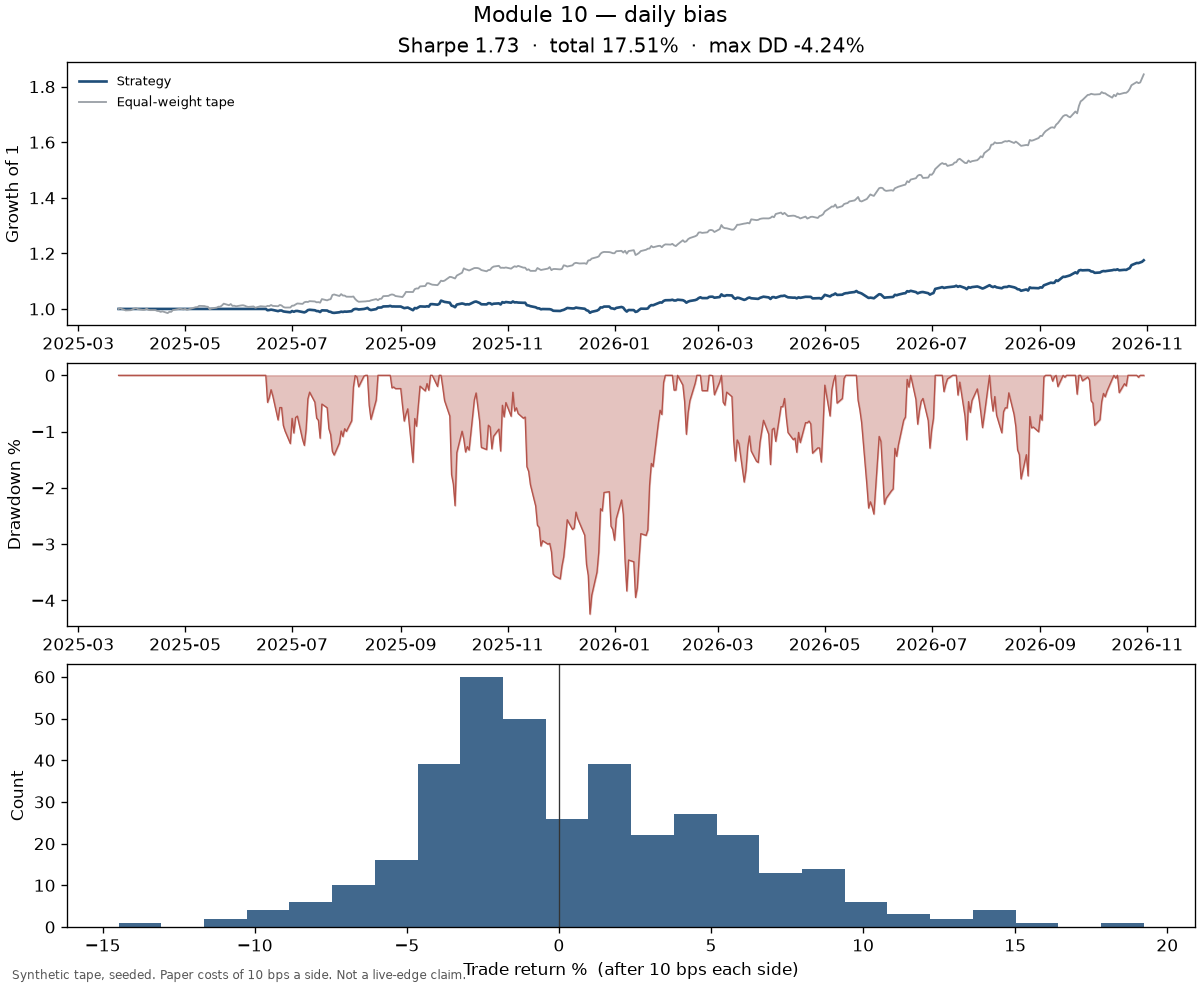

In [3]:
from IPython.display import Image, display

fig_dir = ROOT / "pipeline" / "research" / "notebooks" / "validation" / "figures"
fig_path = fig_dir / "11_daily_bias.png"
fig = draw_module(result, fig_path)
plt.close(fig)
display(Image(filename=str(fig_path)))
